# **FINAL PROJECT MACHINE LEARNING - INVERSE KINEMATICS (STAGE 1)**
### Hernan Vinicio Lopez Morocho  - 30357360


## PROBLEM : 

Machine learning is used for inverse kinematics because analytical solutions are complex, unstable, and slow for high‑DOF robots, while ML learns a fast and robust mapping from position to joint angles using data.
The goal of this project is to design a two‑stage machine learning system for robotic manipulation.
In the first part, a vision‑based neural network predicts the 2D position of a target object from camera images.
In the second stage, a machine‑learning‑based inverse kinematics model predicts the robot joint angles required to reach the detected position.
The system is trained using synthetic image data and synthetic kinematic data and is validated in a simulated robotic environment.


## METODOLOGY

(1) Cube → Photo Image → ML → (x, y)

(2) (x, y) → ML → joint angles arm robot


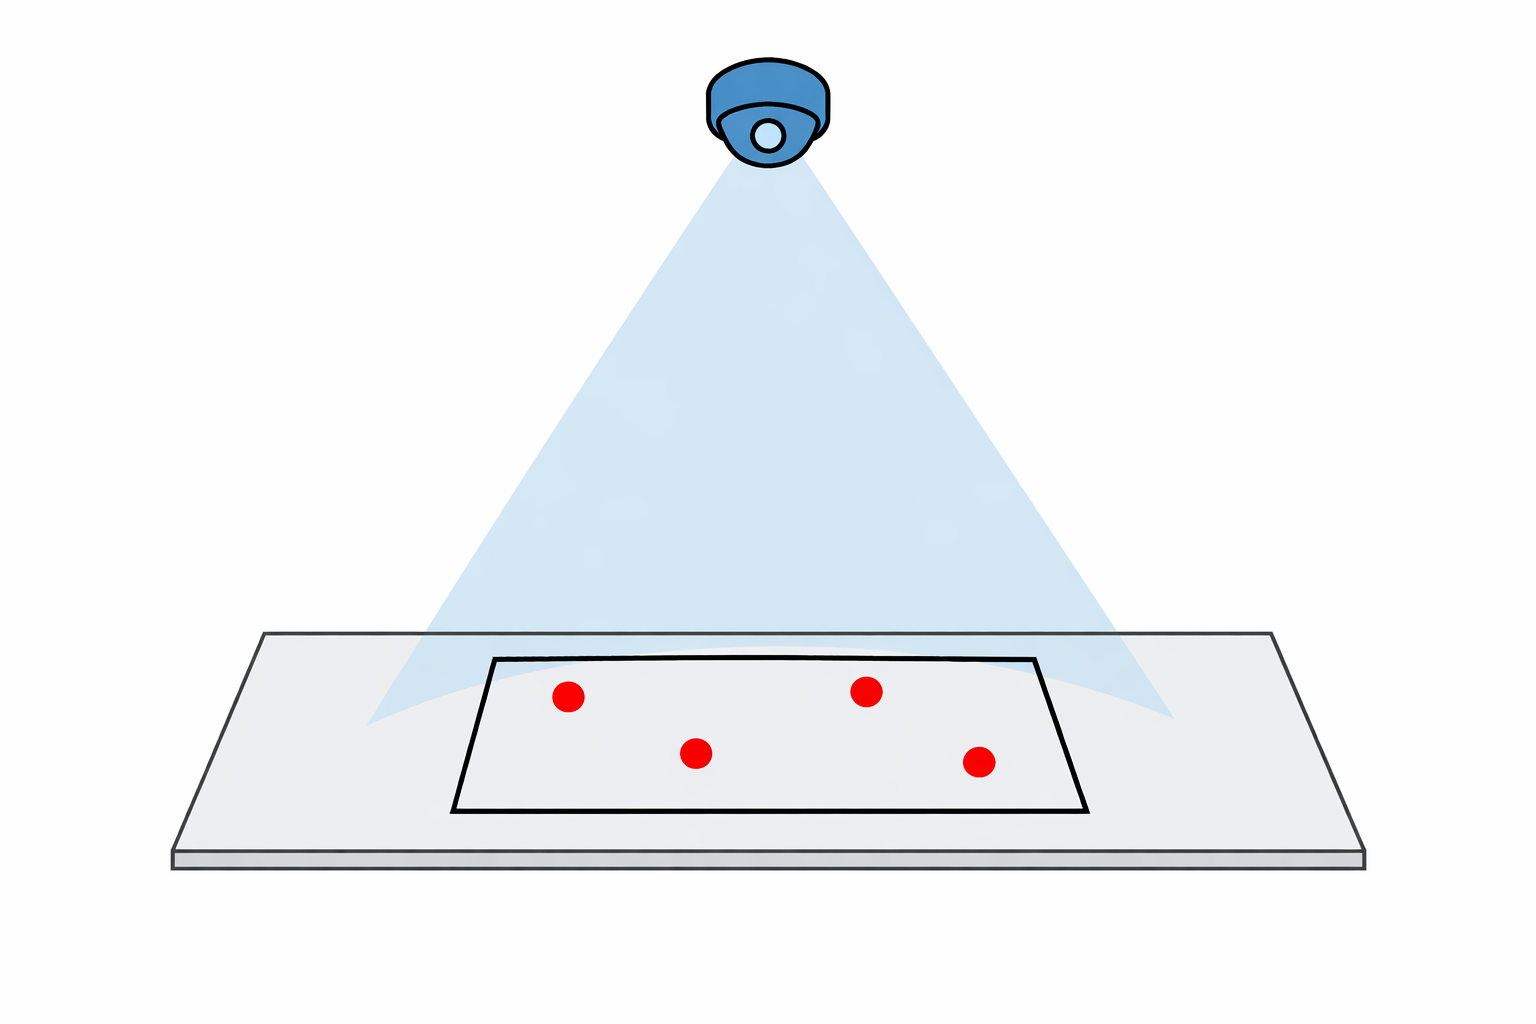 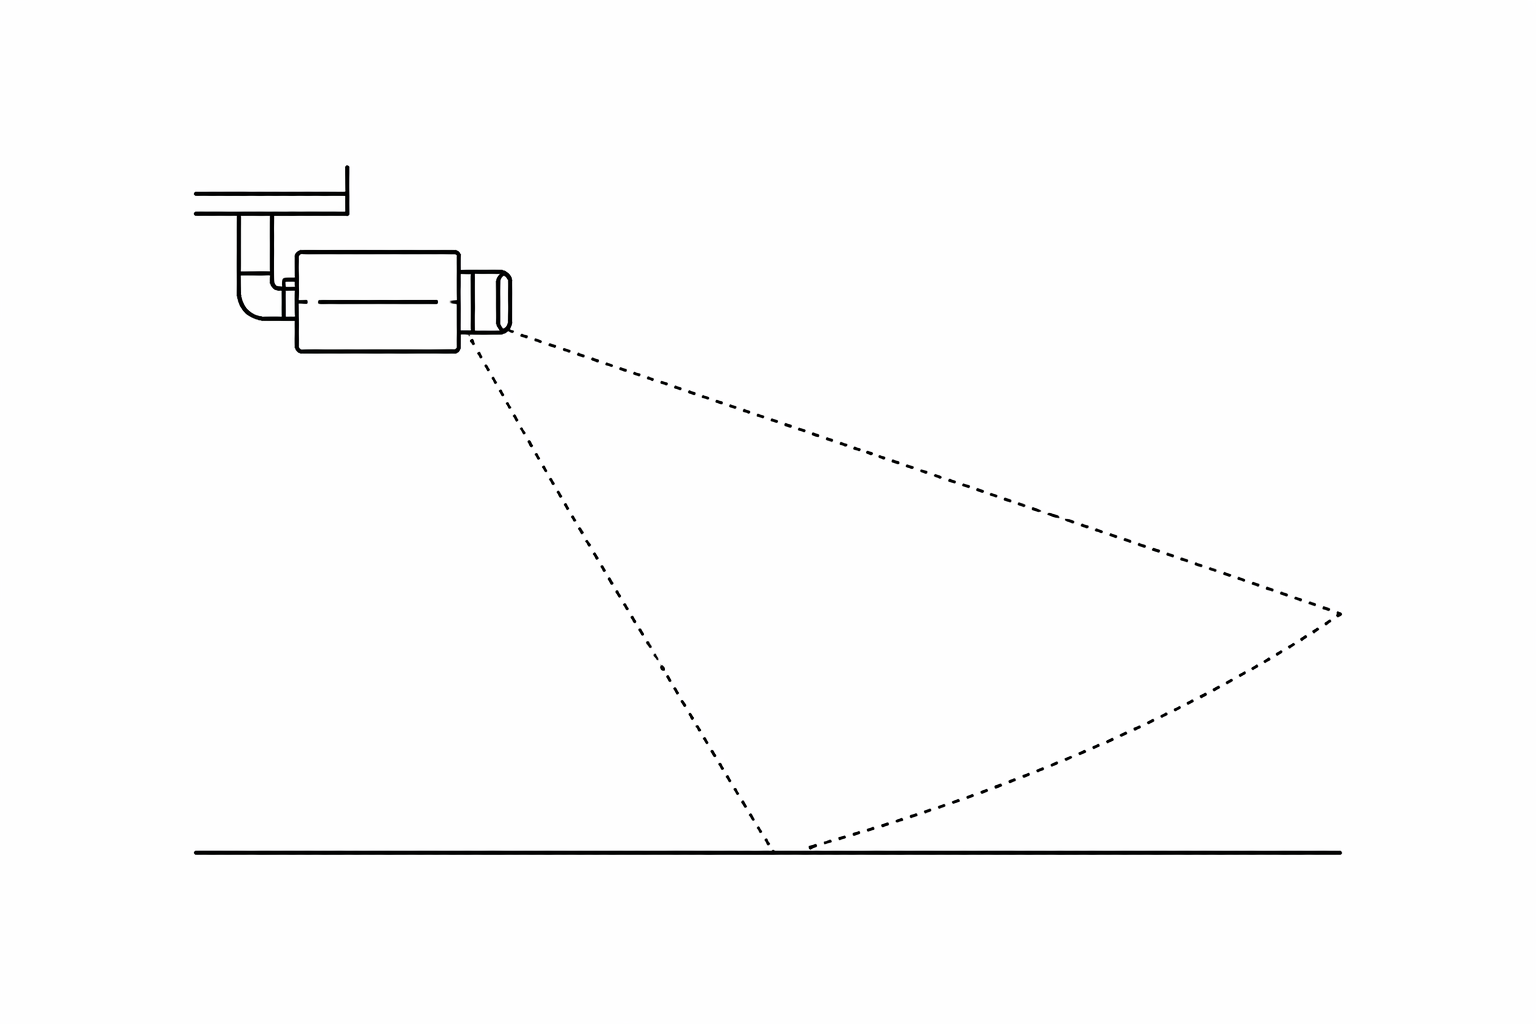

In [2]:
import pybullet as p
import pybullet_data
import numpy as np
import cv2
import os
from tqdm import trange
import random

## DATA SET

In [4]:
OUT_DIR = "data_sim"
IM_DIR = os.path.join(OUT_DIR, "images")
os.makedirs(IM_DIR, exist_ok=True)
LABEL_PATH = os.path.join(OUT_DIR, "labels.csv")


In [5]:
p.connect(p.DIRECT)
p.setAdditionalSearchPath(pybullet_data.getDataPath())

In [6]:
# Basic scene
p.loadURDF("plane.urdf")

cube_visual = p.createVisualShape(p.GEOM_BOX,
                                  halfExtents=[0.03,0.03,0.03],
                                  rgbaColor=[1,0,0,1])  
cube_collision = p.createCollisionShape(p.GEOM_BOX,
                                        halfExtents=[0.03,0.03,0.03])

In [7]:

start_pos = [0.5, 0, 0.1]
start_ori = p.getQuaternionFromEuler([0,0,0])
obj_id = p.createMultiBody(baseMass=0.0,
                           baseCollisionShapeIndex=cube_collision,
                           baseVisualShapeIndex=cube_visual,
                           basePosition=start_pos,
                           baseOrientation=start_ori)

In [8]:
# Camera sampler
IMG_W = 224
IMG_H = 224
FOV = 60
NEAR = 0.01
FAR = 3.0
aspect = IMG_W / IMG_H

def sample_random_scene():
    # Randomize object position 
    x = random.uniform(0.35, 0.75)
    y = random.uniform(-0.2, 0.2)
    z = random.uniform(0.05, 0.25)
    pos = [x, y, z]
    # random orientation
    ori = p.getQuaternionFromEuler([0, 0, 0])
    # random color
    color = [random.random(), random.random(), random.random(), 1.0]
    p.resetBasePositionAndOrientation(obj_id, pos, ori)
    p.changeVisualShape(obj_id, -1, rgbaColor=color)
    return pos

In [9]:
def render_and_label(i):
    # Randomize camera slightly (or fix it)
    cam_target = [0.6, 0, 0.1]  # center-looking target
    cam_pos = [0.2, 0.0, 0.35 + random.uniform(-0.02,0.02)]  # small jitter
    up_vector = [0,0,1]

    view_matrix = p.computeViewMatrix(cameraEyePosition=cam_pos,
                                      cameraTargetPosition=cam_target,
                                      cameraUpVector=up_vector)
    proj_matrix = p.computeProjectionMatrixFOV(fov=FOV,
                                               aspect=aspect,
                                               nearVal=NEAR,
                                               farVal=FAR)
    w, h, rgb, depth, seg = p.getCameraImage(width=IMG_W, height=IMG_H,
                                             viewMatrix=view_matrix,
                                             projectionMatrix=proj_matrix,
                                             renderer=p.ER_BULLET_HARDWARE_OPENGL)
    rgb_array = np.reshape(rgb, (h, w, 4))[:, :, :3]  # discard alpha
    rgb_array = cv2.cvtColor(rgb_array, cv2.COLOR_RGB2BGR)
# segmentation mask: seg is a flat array with objectUniqueId or -1 for background
    seg = np.reshape(seg, (h, w))

    # object pixels where seg == obj_id
    mask = (seg == obj_id)
    if mask.sum() == 0:
        # object not visible in camera - skip or handle as occlusion case
        return None

    # centroid in pixel coords
    ys, xs = np.where(mask)
    cx = int(xs.mean())
    cy = int(ys.mean())

    img_fname = f"img_{i:05d}.png"
    cv2.imwrite(os.path.join(IM_DIR, img_fname), rgb_array)
    return img_fname, cx, cy

In [10]:
N = 8000  
with open(LABEL_PATH, "w") as f:
    f.write("filename,cx,cy,width,height\n")
    for i in trange(N):
        sample_random_scene()
        out = render_and_label(i)
        if out is None:
            # skip if object not visible
            continue
        img_fname, cx, cy = out
        f.write(f"{img_fname},{cx},{cy},{IMG_W},{IMG_H}\n")

p.disconnect()
print("Done.")

100%|██████████| 8000/8000 [03:18<00:00, 40.37it/s]

Done.


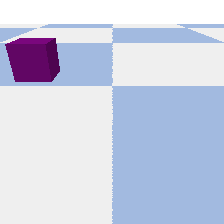 

# MODELS



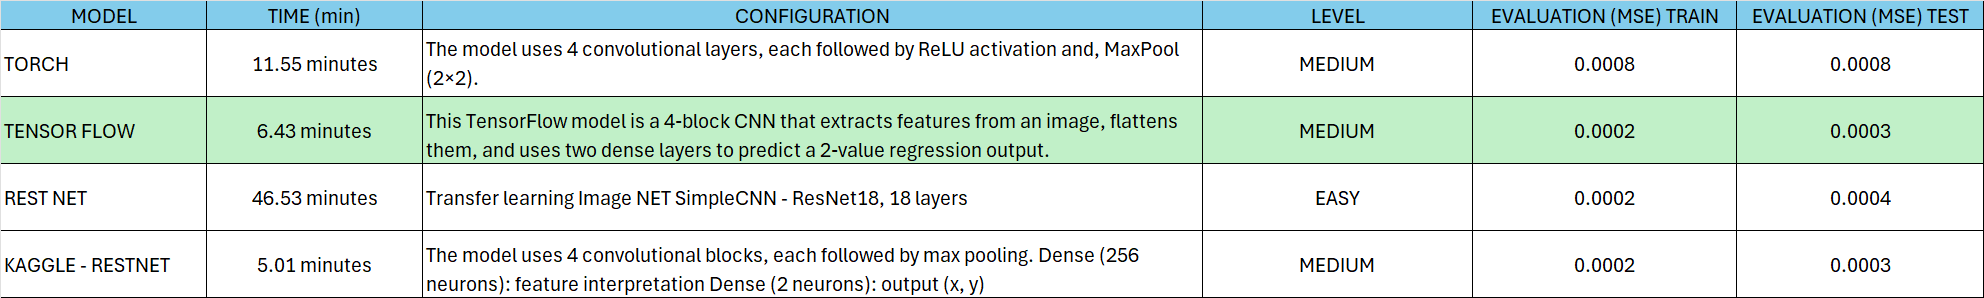

## **CNN - TORCH** 

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, random_split
from torchvision import transforms, models
from PIL import Image
import pandas as pd
import os


### CUSTOM DATA SET

In [2]:
class CubeDataset(Dataset):
    def __init__(self, csv_path, img_dir, transform=None):
        self.data = pd.read_csv(csv_path)
        self.data['cx'] = self.data['cx'] / 224.0
        self.data['cy'] = self.data['cy'] / 224.0
        self.img_dir = img_dir
        self.transform = transform

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        row = self.data.iloc[idx]
        img_path = f"{self.img_dir}/{row['filename']}"
        image = Image.open(img_path).convert("RGB")
        if self.transform:
            image = self.transform(image)
        label = torch.tensor([row['cx'], row['cy']], dtype=torch.float32)
        return image, label

### DATA TRANSFORMS

In [3]:
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
])

dataset = CubeDataset("data_sim/labels.csv", "data_sim/images", transform=transform)

# Split into 80% train, 20% test
train_size = int(0.8 * len(dataset))
test_size = len(dataset) - train_size
train_set, test_set = random_split(dataset, [train_size, test_size])

train_loader = DataLoader(train_set, batch_size=32, shuffle=True)
test_loader = DataLoader(test_set, batch_size=32, shuffle=False)

In [4]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import time 

class SimpleCNN(nn.Module):
    def __init__(self):
        super(SimpleCNN, self).__init__()

        self.conv1 = nn.Conv2d(3, 16, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, padding=1)
        self.conv3 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.conv4 = nn.Conv2d(64, 128, kernel_size=3, padding=1)

        self.pool = nn.MaxPool2d(2, 2)

        # After 4 poolings: 224 → 112 → 56 → 28 → 14
        self.fc1 = nn.Linear(128 * 14 * 14, 256)
        self.fc2 = nn.Linear(256, 2)  # output: x, y

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = self.pool(F.relu(self.conv3(x)))
        x = self.pool(F.relu(self.conv4(x)))

        x = x.view(x.size(0), -1)

        x = F.relu(self.fc1(x))
        x = self.fc2(x)
        return x

In [5]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = SimpleCNN().to(device)
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

strt_time = time.time()

epochs = 10

for epoch in range(epochs):
    model.train()
    total_loss = 0

    for imgs, labels in train_loader:
        imgs, labels = imgs.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(imgs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    print(f"Epoch {epoch+1}/{epochs} - Loss: {total_loss/len(train_loader):.4f}")

torch.save(model.state_dict(), "simple_cnn_position.pth")
torch.save(model, "full_model_complete.pth")
fin_time = time.time()
print(f"Training time: {(fin_time - strt_time)/60:.2f} minutes")
print("Model saved!")

Epoch 1/10 - Loss: 0.0251
Epoch 2/10 - Loss: 0.0028
Epoch 3/10 - Loss: 0.0015
Epoch 4/10 - Loss: 0.0011
Epoch 5/10 - Loss: 0.0009
Epoch 6/10 - Loss: 0.0007
Epoch 7/10 - Loss: 0.0007
Epoch 8/10 - Loss: 0.0006
Epoch 9/10 - Loss: 0.0006
Epoch 10/10 - Loss: 0.0005
Training time: 17.23 minutes
Model saved!


In [6]:
model = SimpleCNN().to(device)
model.load_state_dict(torch.load("simple_cnn_position.pth", map_location=device))
model.eval()

total_loss = 0
with torch.no_grad():
    for imgs, labels in test_loader:
        imgs, labels = imgs.to(device), labels.to(device)
        outputs = model(imgs)
        loss = criterion(outputs, labels)
        total_loss += loss.item()

print(f"Test MSE Loss: {total_loss/len(test_loader):.4f}")

Test MSE Loss: 0.0003


## **TENSOR FLOW** 

In [7]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.models import load_model
import pandas as pd
import numpy as np
import os
from PIL import Image

In [8]:
class CubeDataset(tf.keras.utils.Sequence):
    def __init__(self, csv_path, img_dir, batch_size=32, shuffle=True):
        self.data = pd.read_csv(csv_path)
        self.img_dir = img_dir
        self.batch_size = batch_size
        self.shuffle = shuffle
        self.indexes = np.arange(len(self.data))
        self.on_epoch_end()

    def __len__(self):
        return len(self.data) // self.batch_size

    def on_epoch_end(self):
        if self.shuffle:
            np.random.shuffle(self.indexes)

    def __getitem__(self, idx):
        batch_idx = self.indexes[idx*self.batch_size:(idx+1)*self.batch_size]
        batch_imgs = []
        batch_labels = []

        for i in batch_idx:
            row = self.data.iloc[i]
            img_path = os.path.join(self.img_dir, row["filename"])
            img = Image.open(img_path).convert("RGB")
            img = img.resize((224, 224))
            img = np.array(img) / 255.0

            batch_imgs.append(img.astype(np.float32))
            # CSV uses columns 'cx' and 'cy' (pixel coords). Normalize by width/height if present.
            if 'width' in self.data.columns:
                width = int(row['width'])
            else:
                width = 224
            if 'height' in self.data.columns:
                height = int(row['height'])
            else:
                height = 224
            cx = float(row['cx']) / width
            cy = float(row['cy']) / height
            batch_labels.append([cx, cy])

        return np.array(batch_imgs, dtype=np.float32), np.array(batch_labels, dtype=np.float32)

In [9]:
df = pd.read_csv("data_sim/labels.csv")
train_df = df.sample(frac=0.8, random_state=42)
test_df = df.drop(train_df.index)

train_df.to_csv("train.csv", index=False)
test_df.to_csv("test.csv", index=False)

train_loader = CubeDataset("train.csv", "data_sim/images", batch_size=32)
test_loader = CubeDataset("test.csv", "data_sim/images", batch_size=32, shuffle=False)

In [10]:

def build_model():
    model = models.Sequential([
        layers.Input(shape=(224, 224, 3)),

        layers.Conv2D(16, 3, activation='relu', padding='same'),
        layers.MaxPooling2D(),

        layers.Conv2D(32, 3, activation='relu', padding='same'),
        layers.MaxPooling2D(),

        layers.Conv2D(64, 3, activation='relu', padding='same'),
        layers.MaxPooling2D(),

        layers.Conv2D(128, 3, activation='relu', padding='same'),
        layers.MaxPooling2D(),

        layers.Flatten(),
        layers.Dense(256, activation='relu'),
        layers.Dense(2)  # x, y output
    ])

    model.compile(optimizer='adam', loss='mse')
    return model

model = build_model()
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 224, 224, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 32)   │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     6,422,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │           514 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,520,738 (24.87 MB)

 Trainable params: 6,520,738 (24.87 MB)

 Non-trainable params: 0 (0.00 B)

In [11]:
strt_time = time.time()
history = model.fit(
    train_loader,
    validation_data=test_loader,
    epochs=10
)
fin_time = time.time()
print(f"Training time: {(fin_time - strt_time)/60:.2f} minutes")
#model.save("keras_cnn_position.keras")

Epoch 1/10


c:\Users\herna\anaconda3\Lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


198/198 ━━━━━━━━━━━━━━━━━━━━ 38s 186ms/step - loss: 0.0682 - val_loss: 0.0035
Epoch 2/10
198/198 ━━━━━━━━━━━━━━━━━━━━ 45s 228ms/step - loss: 0.0023 - val_loss: 0.0030
Epoch 3/10
198/198 ━━━━━━━━━━━━━━━━━━━━ 25s 126ms/step - loss: 0.0018 - val_loss: 0.0013
Epoch 4/10
198/198 ━━━━━━━━━━━━━━━━━━━━ 23s 115ms/step - loss: 0.0014 - val_loss: 0.0017
Epoch 5/10
198/198 ━━━━━━━━━━━━━━━━━━━━ 23s 116ms/step - loss: 8.3941e-04 - val_loss: 8.9488e-04
Epoch 6/10
198/198 ━━━━━━━━━━━━━━━━━━━━ 23s 115ms/step - loss: 4.5148e-04 - val_loss: 5.9869e-04
Epoch 7/10
198/198 ━━━━━━━━━━━━━━━━━━━━ 23s 115ms/step - loss: 5.7159e-04 - val_loss: 9.9386e-04
Epoch 8/10
198/198 ━━━━━━━━━━━━━━━━━━━━ 23s 117ms/step - loss: 4.3512e-04 - val_loss: 4.9488e-04
Epoch 9/10
198/198 ━━━━━━━━━━━━━━━━━━━━ 36s 181ms/step - loss: 3.0636e-04 - val_loss: 3.4396e-04
Epoch 10/10
198/198 ━━━━━━━━━━━━━━━━━━━━ 39s 198ms/step - loss: 2.7731e-04 - val_loss: 5.0231e-04
Training time: 4.96 minutes


## **REST NET** 

### MODEL SETUP


In [12]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import models

model = models.resnet18(pretrained=True)
model.fc = nn.Linear(512, 2)  # output: x, y

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)

criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=1e-4)


c:\Users\herna\anaconda3\Lib\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
c:\Users\herna\anaconda3\Lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


### TRAININNG LOOPS 

In [ ]:
import time
epochs = 10

start_time = time.time()

for epoch in range(epochs):
    model.train()
    total_loss = 0
    for imgs, labels in train_loader:
        imgs = torch.as_tensor(imgs, dtype=torch.float32).to(device)
        labels = torch.as_tensor(labels, dtype=torch.float32).to(device)
        imgs = imgs.permute(0, 3, 1, 2)
        optimizer.zero_grad()
        outputs = model(imgs)
        optimizer.zero_grad()
        outputs = model(imgs)
        imgs, labels = imgs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(imgs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    print(f"Epoch {epoch+1}/{epochs} - Loss: {total_loss/len(train_loader):.4f}")


torch.save(model.state_dict(), "cube_position_model.pth")
end_time = time.time()
total_duration = (end_time - start_time)/60
print(f"Training finished in {total_duration:.2f} minutes")
print("Model saved!")

Epoch 1/10 - Loss: 0.0183
Epoch 2/10 - Loss: 0.0011
Epoch 3/10 - Loss: 0.0005
Epoch 4/10 - Loss: 0.0007
Epoch 5/10 - Loss: 0.0009
Epoch 6/10 - Loss: 0.0004
Epoch 7/10 - Loss: 0.0003
Epoch 8/10 - Loss: 0.0002
Epoch 9/10 - Loss: 0.0002
Epoch 10/10 - Loss: 0.0002
Training finished in 72.77 minutes
Model saved!


### TESTING EVALUATION

In [19]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

In [ ]:
model.eval()
total_loss = 0
with torch.no_grad():
    for imgs, labels in test_loader:
        imgs = torch.as_tensor(imgs, dtype=torch.float32).to(device)
        labels = torch.as_tensor(labels, dtype=torch.float32).to(device)
        
        imgs = imgs.permute(0, 3, 1, 2)
        
        outputs = model(imgs)
        loss = criterion(outputs, labels)
        total_loss += loss.item()

print(f"\nTest MSE Loss: {total_loss/len(test_loader):.4f}")



Test MSE Loss: 0.0005


## **KAGGLE** 

https://www.kaggle.com/code/hernanvlopez/1-inversekinematics

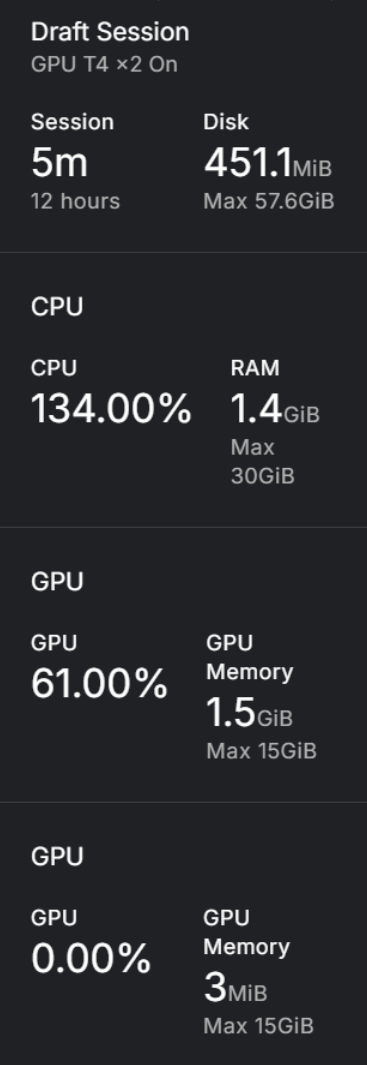

### **VIZ**

In [22]:
from PIL import Image, ImageDraw

# Load model
model = tf.keras.models.load_model("keras_cnn_position.keras")

# Load labels
df = pd.read_csv(r"data_sim/labels.csv")
# Test img_0000xxxx
img_name = "img_00049.png"
truth = df[df['filename'] == img_name].iloc[0]

# Load image
img = Image.open(f"data_sim/images/{img_name}").resize((224, 224))
img_array = np.array(img) / 255.0

# Predict
pred = model.predict(img_array[None, ...], verbose=0)[0]
pred_x, pred_y = pred[0] * 224, pred[1] * 224

# Draw
draw = ImageDraw.Draw(img)
draw.ellipse([pred_x-8, pred_y-8, pred_x+8, pred_y+8], outline='red', width=3)  # Pred
draw.line([(truth['cx']-8, truth['cy']-8), (truth['cx']+8, truth['cy']+8)], fill='green', width=3)  # Truth
draw.line([(truth['cx']-8, truth['cy']+8), (truth['cx']+8, truth['cy']-8)], fill='green', width=3)  # Truth

img.save("result.png")
print(f"Pred: ({pred_x:.0f}, {pred_y:.0f}) | Truth: ({truth['cx']}, {truth['cy']})")
print(f"Position in m:{pred_y/224:.2f}, {pred_x/224:.2f} ")
x1 = ((pred_x/224)*0.8)
y1 = (((244-pred_y)/224)*0.8)
cube_pos = np.array([x1, y1, 0.01])
np.save("cube_pos.npy", cube_pos)

img.show()

Pred: (47, 78) | Truth: (47, 78)
Position in m:0.35, 0.21 


In [23]:
!python kuka.py

starting thread 0
started testThreads thread 0 with threadHandle 0000000000000208
argc=2
argv[0] = --unused
argv[1] = --start_demo_name=Physics Server
ExampleBrowserThreadFunc started
Version = 4.6.0 - Build 32.0.101.7082
Vendor = Intel
Renderer = Intel(R) RaptorLake-S Mobile Graphics Controller
b3Printf: Selected demo: Physics Server
starting thread 0
started MotionThreads thread 0 with threadHandle 0000000000000548
MotionThreadFunc thread started
Cube position: [0.16845549 0.5925613  0.01      ]
Target position: [0.1684554934501648, 0.5925613028662545, 0.11]
Step 0: End-effector at ['0.000', '0.000', '1.281']
Step 100: End-effector at ['0.445', '0.308', '1.061']
Step 200: End-effector at ['0.371', '0.664', '0.562']
Step 300: End-effector at ['0.166', '0.596', '0.110']
Step 400: End-effector at ['0.161', '0.587', '0.092']
Step 500: End-effector at ['0.155', '0.592', '0.110']
Step 600: End-effector at ['-0.104', '0.426', '0.490']
Step 700: End-effector at ['-0.068', '0.498', '0.513']
S

pybullet build time: Oct 21 2025 10:47:45
Traceback (most recent call last):
  File "c:\Users\herna\Documents\Hernan_Documentos\ml\mlrobot\kuka.py", line 44, in <module>
    joint_angles = p.calculateInverseKinematics(
                   ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
pybullet.error: Not connected to physics server.
